Importing libraries:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

Load Dataset:

In [2]:
dataset=pd.read_csv("Mall_Customers.csv")

Features Split:

In [3]:
X=dataset.iloc[:,[3,4]].values

Find the Best clusters using Dendrogram:

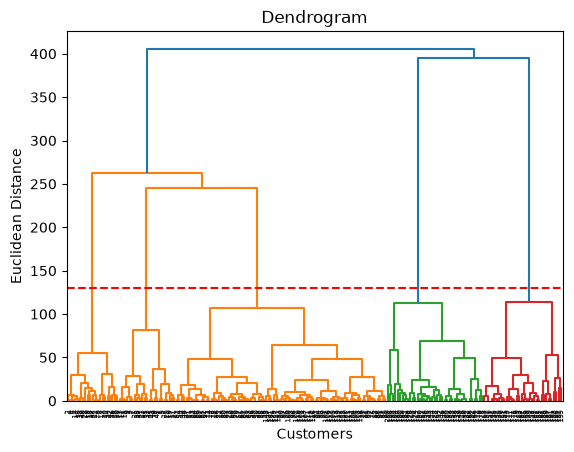

In [4]:
import scipy.cluster.hierarchy as sch
dendrogram=sch.dendrogram(sch.linkage(X,method='ward'),labels=dataset['CustomerID'].values)
plt.axhline(y=130, color='r', linestyle='--')
plt.title("Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Euclidean Distance")
plt.show()

Standard Scaler:

In [5]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X_scaled=sc.fit_transform(X)

Train a Model:

In [6]:
from sklearn.cluster import AgglomerativeClustering
cluster=AgglomerativeClustering(n_clusters=5)
labels=cluster.fit_predict(X_scaled)

Display the Cluster lables:

In [7]:
labels

array([4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3,
       4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 2,
       4, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 2, 1, 0, 1, 0, 1,
       2, 1, 0, 1, 0, 1, 0, 1, 0, 1, 2, 1, 0, 1, 2, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 2, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1])

Create a DataFrame to Existing Dataset:

In [8]:
clustered_Dataset=pd.DataFrame(dataset)

Add Labels to the Existing Dataset:

In [9]:
clustered_Dataset["Clustered_Group"]=labels
clustered_Dataset

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Clustered_Group
0,1,Male,19,15,39,4
1,2,Male,21,15,81,3
2,3,Female,20,16,6,4
3,4,Female,23,16,77,3
4,5,Female,31,17,40,4
...,...,...,...,...,...,...
195,196,Female,35,120,79,1
196,197,Female,45,126,28,0
197,198,Male,32,126,74,1
198,199,Male,32,137,18,0


Plot the Cluster's Graph:

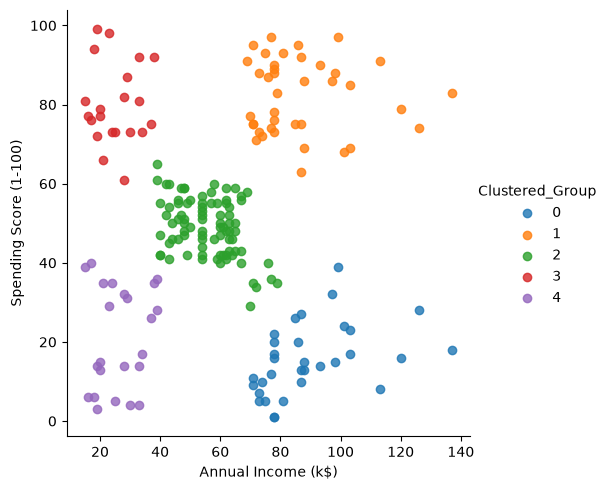

In [10]:
import seaborn as sns
facet=sns.lmplot(data=clustered_Dataset,x=clustered_Dataset.columns[3],y=clustered_Dataset.columns[4],hue=clustered_Dataset.columns[5],
                fit_reg=False,legend=True)
facet

Evaluation Metrics:

In [11]:
from sklearn.metrics import silhouette_score
score=silhouette_score(X_scaled,labels)
print("The Model Segregated score(-1 to +1) :",score)

The Model Segregated score(-1 to +1) : 0.5538089226688662


Average Annual Income and Spending Score by Cluster for Final Understanding:

In [12]:
cluster_profile=clustered_Dataset.groupby('Clustered_Group')[
    ['Annual Income (k$)','Spending Score (1-100)']
    ].mean()
print(cluster_profile)

                 Annual Income (k$)  Spending Score (1-100)
Clustered_Group                                            
0                         89.406250               15.593750
1                         86.538462               82.128205
2                         55.811765               49.129412
3                         25.095238               80.047619
4                         26.304348               20.913043


Count the Dataset Lables Based on Uniques:

In [13]:
print(clustered_Dataset['Clustered_Group'].value_counts())

Clustered_Group
2    85
1    39
0    32
4    23
3    21
Name: count, dtype: int64
